# Baseline 1 — Independent ViT-B/16
Two independent ImageNet-pretrained torchvision networks, each with one linear crop or disease head. No composition head, shared parameters, freezing, added dropout, smoothing or warmup. Each returns 768-dimensional features; concatenation is 1536-dimensional.

**Run All:** dev selection, fresh final retraining, then test evaluation automatically. Defaults: seed 42, 20 dev epochs, uniform AdamW 3e-5, weight decay 0.05, separate epoch cosine schedules. Colab T4 uses AMP, microbatch 8 × accumulation 4 (effective 32), evaluation batch 8. Crop forward/backward completes before disease forward/backward; final partial windows normalize by actual examples.

**Protocol:** ResNet's deterministic pseudo-unseen split chooses one paired checkpoint and calibrated bias. Final retrains on all training data for the dev-selected epoch count. Test labels do not select the reported model or bias. Independent argmax results are separate from valid-composition scoring.

**Comparison caveat:** current Baseline 2 ViT includes a composition head and seen-test checkpoint selection, so this is not a controlled comparison. Augmentation operators match its ViT transforms, but the reused ResNet cache adds EXIF correction, 320-pixel resizing and re-encoding: input pixels differ from current Baseline 2 ViT. No automated cross-baseline comparison or public GUI.

No recorded results. Execution may mount Drive, extract/cache data, download weights, train and write checkpoints. Setup cells install missing dependencies; archive extraction requires `7z` (not needed for extracted data).

## 1. Setup

Local Windows bootstrap (this line is need if the libraries are already installed and run once from the repository root):
```powershell
py -3.12 -m venv .venv
& .\.venv\Scripts\python.exe -m pip install --upgrade pip
& .\.venv\Scripts\python.exe -m pip install --no-cache-dir ipykernel
& .\.venv\Scripts\python.exe -m pip install --no-cache-dir torch==2.7.1 torchvision==0.22.1 --index-url https://download.pytorch.org/whl/cu128
& .\.venv\Scripts\python.exe -m pip install --no-cache-dir numpy pandas pillow matplotlib scikit-learn jinja2
& .\.venv\Scripts\python.exe -c "import torch; print(torch.__version__, torch.version.cuda, torch.cuda.is_available(), torch.cuda.get_device_name(0))"
```
Select `.venv\Scripts\python.exe` as the VS Code notebook interpreter, then **Run All**. The next cells configure repo-local runtime paths and install missing dependencies before scientific imports. Do not register a user-wide kernel. VS Code/Jupyter host state created before these cells may still live outside the repository; launch the host with the same environment variables if that state must also stay local. Restart the kernel after changing packages that were already imported.

Local defaults target RTX 4050 6 GB: microbatch 4 × accumulation 8 (effective batch 32); only one task's parameters/optimizer occupy the GPU at once. Substantial CPU RAM and checkpoint disk space are needed; memory fit is unverified. Colab keeps GPU defaults and mounts Drive. No public server is launched. Existing external environments are untouched.

Data: `<repo>/DPD_Small`. Cache/weights/temp: `<repo>/.runtime`. All checkpoints, tables and plots: `Baseline1/ViT Backbone/runs`. Run All resumes interrupted dev/final phases separately; incompatible checkpoints raise rather than being deleted. No mode edits or restart between phases.

In [1]:
import os, sys, json, time, math, random, shutil, subprocess, tempfile, gc
from pathlib import Path
import importlib.util
import importlib.metadata

IN_COLAB = 'google.colab' in sys.modules
if not IN_COLAB and importlib.util.find_spec('google') is not None:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
LOCAL_REPO_ROOT = None  # only needed when launching outside the checkout

def locate_repo(override=None):
    if override:
        root = Path(override).expanduser().resolve()
        if (root / 'Baseline1').is_dir() and (root / 'Baseline2').is_dir():
            return root
        raise FileNotFoundError('LOCAL_REPO_ROOT must point to the checkout.')
    here = Path.cwd().resolve()
    for root in (here, *here.parents):
        if (root / 'Baseline1').is_dir() and (root / 'Baseline2').is_dir():
            return root
    raise FileNotFoundError('Set LOCAL_REPO_ROOT to the checkout.')

def project_path(value, parent, label):
    path = Path(value).expanduser()
    path = (path if path.is_absolute() else repo_root / path).resolve()
    if not path.is_relative_to(parent):
        raise ValueError(f'{label} must remain inside {parent}: {path}')
    return path

if not IN_COLAB:
    repo_root = locate_repo(LOCAL_REPO_ROOT)
    runtime_root = project_path(repo_root / '.runtime', repo_root, 'runtime')
    locations = {'TEMP': 'tmp', 'TMP': 'tmp', 'TMPDIR': 'tmp', 'TORCH_HOME': 'torch',
                 'XDG_CACHE_HOME': 'cache', 'MPLCONFIGDIR': 'matplotlib',
                 'JUPYTER_CONFIG_DIR': 'jupyter/config', 'JUPYTER_DATA_DIR': 'jupyter/data',
                 'JUPYTER_RUNTIME_DIR': 'jupyter/runtime', 'IPYTHONDIR': 'ipython'}
    for key, relative in locations.items():
        path = project_path(runtime_root / relative, runtime_root, key)
        path.mkdir(parents=True, exist_ok=True)
        os.environ[key] = str(path)
    tempfile.tempdir = os.environ['TEMP']
    os.environ['PIP_NO_CACHE_DIR'] = '1'
print('Colab' if IN_COLAB else f'Local kernel: {sys.executable}')

Local kernel: c:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30082 APPLIED MACHINE LEARNING\Group_ML Assignment\COS30082-ML-Project\.venv\Scripts\python.exe


In [2]:
def pip_install(*packages, extra=()):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-cache-dir', *packages, *extra], check=True)

if not IN_COLAB:
    installed = [importlib.util.find_spec(p) is not None for p in ('torch', 'torchvision')]
    if not any(installed):
        pip_install('torch==2.7.1', 'torchvision==0.22.1',
                    extra=('--index-url', 'https://download.pytorch.org/whl/cu128'))
    elif not all(installed) or any(importlib.metadata.version(p).split('+')[0] != v
                                   for p, v in [('torch', '2.7.1'), ('torchvision', '0.22.1')]):
        raise RuntimeError('Local torch/torchvision mismatch. In this kernel environment install torch==2.7.1 torchvision==0.22.1 from https://download.pytorch.org/whl/cu128, then restart. Existing packages are not automatically replaced.')
else:
    if not all(importlib.util.find_spec(p) for p in ('torch', 'torchvision')):
        raise RuntimeError('Select a standard Colab GPU runtime with torch and torchvision preinstalled.')

packages = {'numpy': 'numpy', 'pandas': 'pandas', 'PIL': 'pillow', 'matplotlib': 'matplotlib',
            'sklearn': 'scikit-learn', 'ipykernel': 'ipykernel', 'jinja2': 'jinja2', 'tqdm': 'tqdm'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    pip_install(*missing)

import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision import models as tv_models
import hashlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import confusion_matrix

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'
if not AMP:
    raise RuntimeError('CUDA unavailable. Colab: select GPU. Local: verify NVIDIA driver and a CUDA torch wheel; if CPU-only, reinstall torch==2.7.1 torchvision==0.22.1 with --index-url https://download.pytorch.org/whl/cu128 using this interpreter, then restart. No automatic replacement/download is attempted.')
if not IN_COLAB and torch.version.cuda != '12.8':
    raise RuntimeError('Expected local cu128 torch wheel. Install the pinned cu128 pair explicitly and restart.')
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
print('device:', torch.cuda.get_device_name(0), '| torch:', torch.__version__)

c:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30082 APPLIED MACHINE LEARNING\Group_ML Assignment\COS30082-ML-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: NVIDIA GeForce RTX 4050 Laptop GPU | torch: 2.7.1+cu128


### Configuration
Review defaults once; dev and final run automatically. Preserve incompatible checkpoints.

In [3]:
CFG = dict(
    drive_root='/content/drive/MyDrive/COS30082', archive_name='DPD_Small.7z', dataset_dir=None,
    data_root='/content/data', local_root='/content', cache_size=320,
    backbone='vit_b_16', weights='ViT_B_16_Weights.DEFAULT', img_size=224,
    batch_size=8, accumulation_steps=4, eval_batch_size=8,
    epochs=20, lr=3e-5, weight_decay=0.05,
    num_holdout_pairs=15, val_frac=0.1, num_workers=2, seed=42, low_memory=False,
)
if not IN_COLAB:
    CFG.update(drive_root=str(repo_root), dataset_dir=str(repo_root / 'DPD_Small'),
               data_root=str(runtime_root / 'data'), local_root=str(runtime_root),
               batch_size=4, accumulation_steps=8, eval_batch_size=16, num_workers=0, low_memory=True)
if os.environ.get('DPD_CFG'):
    overrides = json.loads(os.environ['DPD_CFG'])
    if set(overrides) - set(CFG):
        raise ValueError(f'Unknown configuration keys: {set(overrides) - set(CFG)}')
    CFG.update(overrides)
if not IN_COLAB:
    for key in ('local_root', 'data_root'):
        CFG[key] = str(project_path(CFG[key], runtime_root, key))
    for key in ('drive_root', 'dataset_dir'):
        CFG[key] = str(project_path(CFG[key], repo_root, key))
assert CFG['backbone'] == 'vit_b_16' and CFG['weights'] == 'ViT_B_16_Weights.DEFAULT'
assert CFG['img_size'] == 224 and isinstance(CFG['low_memory'], bool)
assert all(isinstance(CFG[k], int) and CFG[k] > 0 for k in
           ('batch_size', 'accumulation_steps', 'eval_batch_size', 'epochs', 'num_holdout_pairs', 'cache_size'))
assert 0 < CFG['val_frac'] < 1 and CFG['num_workers'] >= 0
assert CFG['lr'] > 0 and CFG['weight_decay'] >= 0
if (os.name == 'nt' or CFG['low_memory']) and CFG['num_workers'] != 0:
    raise ValueError('Windows notebooks and low_memory mode require num_workers=0.')
PROTOCOL = 'independent-vit-b16-pseudo-unseen-v2-auto'
CACHE_DIR = os.path.join(CFG['local_root'], f"dpd_small_{CFG['cache_size']}")
CACHE_ZIP = os.path.join(CFG['drive_root'], 'cache', f"dpd_small_{CFG['cache_size']}.zip")
OUT_DIR = str(Path(CFG['drive_root']) / 'Baseline1' / 'ViT Backbone' / 'runs')
DEV_SUMMARY = os.path.join(OUT_DIR, 'dev_summary.json')
if not IN_COLAB:
    OUT_DIR = str(project_path(repo_root / 'Baseline1/ViT Backbone/runs', repo_root, 'runs'))
    DEV_SUMMARY = str(project_path(Path(OUT_DIR) / 'dev_summary.json', repo_root, 'summary'))
    project_path(CACHE_DIR, runtime_root, 'cache')
    torch.hub.set_dir(str(runtime_root / 'torch/hub'))
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CFG['local_root'], exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(CFG['seed'])
print(json.dumps(CFG, indent=2))
print('effective batch:', CFG['batch_size'] * CFG['accumulation_steps'], '| outputs:', OUT_DIR)

{
  "drive_root": "C:\\Users\\basil\\Documents\\001_Year4_Sem7(Extended)\\COS30082 APPLIED MACHINE LEARNING\\Group_ML Assignment\\COS30082-ML-Project",
  "archive_name": "DPD_Small.7z",
  "dataset_dir": "C:\\Users\\basil\\Documents\\001_Year4_Sem7(Extended)\\COS30082 APPLIED MACHINE LEARNING\\Group_ML Assignment\\COS30082-ML-Project\\DPD_Small",
  "data_root": "C:\\Users\\basil\\Documents\\001_Year4_Sem7(Extended)\\COS30082 APPLIED MACHINE LEARNING\\Group_ML Assignment\\COS30082-ML-Project\\.runtime\\data",
  "local_root": "C:\\Users\\basil\\Documents\\001_Year4_Sem7(Extended)\\COS30082 APPLIED MACHINE LEARNING\\Group_ML Assignment\\COS30082-ML-Project\\.runtime",
  "cache_size": 320,
  "backbone": "vit_b_16",
  "weights": "ViT_B_16_Weights.DEFAULT",
  "img_size": 224,
  "batch_size": 4,
  "accumulation_steps": 8,
  "eval_batch_size": 16,
  "epochs": 20,
  "lr": 3e-05,
  "weight_decay": 0.05,
  "num_holdout_pairs": 15,
  "val_frac": 0.1,
  "num_workers": 0,
  "seed": 42,
  "low_memory"

## 2. Data and augmentation
Retain ResNet EXIF correction, 320-pixel resize and re-encoding for consistent source preprocessing. Local cache is reused without a duplicate ZIP; Colab may unpack an existing cache. These pixels differ from Baseline 2 ViT.

In [4]:
import glob
from concurrent.futures import ThreadPoolExecutor
CSV_NAMES = ['DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_test_unseen.csv']
SRC_IMAGES = os.path.join(CFG['data_root'], 'DPD_Small_dataset')   # replaced if an extracted folder is found on Drive
IMAGE_DIR = os.path.join(CACHE_DIR, 'DPD_Small_dataset')
MY_DRIVE = os.path.dirname(CFG['drive_root'])   # /content/drive/MyDrive

def is_dataset_folder(path):
    return (path is not None and os.path.isdir(os.path.join(path, 'DPD_Small_dataset'))
            and all(os.path.exists(os.path.join(path, n)) for n in CSV_NAMES))

def find_extracted_folder():
    # An already-extracted DPD_Small folder on Drive (3 CSVs + DPD_Small_dataset/), or None
    if CFG['dataset_dir']:
        if not is_dataset_folder(CFG['dataset_dir']):
            raise FileNotFoundError(f"dataset_dir={CFG['dataset_dir']!r} must contain {CSV_NAMES} and DPD_Small_dataset/")
        return CFG['dataset_dir']
    candidates = [os.path.join(CFG['drive_root'], 'DPD_Small'), CFG['drive_root']]
    if os.path.isdir(MY_DRIVE):   # look up to two folders below MyDrive
        for pattern in (('*',), ('*', '*')):
            candidates += sorted(os.path.dirname(p) for p in glob.glob(os.path.join(MY_DRIVE, *pattern, CSV_NAMES[0])))
    return next((c for c in candidates if is_dataset_folder(c)), None)

def extract_archive():
    if os.path.exists(os.path.join(CFG['data_root'], CSV_NAMES[0])):
        return
    archive = os.path.join(CFG['drive_root'], CFG['archive_name'])
    if not os.path.exists(archive):
        raise FileNotFoundError(
            f'No DPD-Small data found. Looked for {CACHE_ZIP}, an extracted DPD_Small folder up to two levels '
            f'below {MY_DRIVE}, and {archive}. Set dataset_dir in the config to the folder holding the CSVs.')
    local_archive = os.path.join(CFG['local_root'], CFG['archive_name'])
    print('copying', archive, 'to local disk ...')
    shutil.copy(archive, local_archive)
    print('extracting ...')
    subprocess.run(['7z', 'x', '-y', local_archive, f"-o{CFG['data_root']}"], check=True, stdout=subprocess.DEVNULL)
    os.remove(local_archive)

# Phone photos store their rotation in an EXIF tag. ImageOps.exif_transpose crashes on
# some DPD images whose EXIF is malformed (e.g. a resolution tag saved as text), so we
# read only the orientation tag ourselves and drop the rest of the EXIF.
ORIENTATION_FIX = {2: Image.Transpose.FLIP_LEFT_RIGHT, 3: Image.Transpose.ROTATE_180,
                   4: Image.Transpose.FLIP_TOP_BOTTOM, 5: Image.Transpose.TRANSPOSE,
                   6: Image.Transpose.ROTATE_270, 7: Image.Transpose.TRANSVERSE,
                   8: Image.Transpose.ROTATE_90}

def load_upright(path):
    with Image.open(path) as im:
        try:
            orientation = im.getexif().get(0x0112, 1)
        except Exception:
            orientation = 1
        im = im.convert('RGB')
    if orientation in ORIENTATION_FIX:
        im = im.transpose(ORIENTATION_FIX[orientation])
    im.info = {}
    return im

def resize_one(name):
    dst = os.path.join(IMAGE_DIR, name)
    if os.path.exists(dst):
        return
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    im = load_upright(os.path.join(SRC_IMAGES, name))
    scale = CFG['cache_size'] / min(im.size)
    if scale < 1:
        im = im.resize((round(im.width * scale), round(im.height * scale)), Image.BICUBIC)
    im.save(dst, quality=95)

def prepare_data():
    global SRC_IMAGES
    done_flag = os.path.join(CACHE_DIR, '.complete')
    if IN_COLAB and not os.path.exists(done_flag) and os.path.exists(CACHE_ZIP):
        print('unpacking resized dataset from Drive ...')
        shutil.unpack_archive(CACHE_ZIP, CFG['local_root'])
    if os.path.exists(done_flag):
        print('dataset ready:', CACHE_DIR)
        return
    src = find_extracted_folder()
    if src:
        print('using the extracted dataset folder on Drive:', src)
    else:
        extract_archive()
        src = CFG['data_root']
    SRC_IMAGES = os.path.join(src, 'DPD_Small_dataset')
    os.makedirs(IMAGE_DIR, exist_ok=True)
    for name in CSV_NAMES:
        shutil.copy(os.path.join(src, name), CACHE_DIR)
    names = pd.concat([pd.read_csv(os.path.join(CACHE_DIR, n), header=None)[0] for n in CSV_NAMES]).unique()
    missing = sorted(set(names) - set(os.listdir(SRC_IMAGES)))   # catches an unfinished Drive upload
    if missing:
        raise FileNotFoundError(f'{len(missing)} of {len(names)} images listed in the CSVs are missing from '
                                f'{SRC_IMAGES} (e.g. {missing[:3]}). Finish the upload and run again.')
    print(f'resizing {len(names)} images (one-off) ...')
    with ThreadPoolExecutor(16) as pool:
        for i, _ in enumerate(pool.map(resize_one, names), 1):
            if i % 1000 == 0:
                print(f'  {i}/{len(names)}')
    open(done_flag, 'w').close()
    print('resized cache ready:', CACHE_DIR)  # no duplicate ZIP

prepare_data()
TRAIN_CSV, TEST_SEEN_CSV, TEST_UNSEEN_CSV = (os.path.join(CACHE_DIR, n) for n in CSV_NAMES)

dataset ready: C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30082 APPLIED MACHINE LEARNING\Group_ML Assignment\COS30082-ML-Project\.runtime\dpd_small_320


### Metadata
All CSVs define admissible vocabulary, as in ResNet; test labels never select weights, epochs or reported bias.

In [5]:
COLS = ['file', 'crop', 'disease', 'comp', 'crop_name', 'disease_name', 'comp_name']

def read_split(path):
    return pd.read_csv(path, header=None, names=COLS)

train_df = read_split(TRAIN_CSV)
test_seen_df = read_split(TEST_SEEN_CSV)
test_unseen_df = read_split(TEST_UNSEEN_CSV)
all_df = pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True)

# Every composition id must map to exactly one (crop, disease) pair
assert (all_df.groupby('comp')[['crop', 'disease']].nunique() == 1).all().all()
comps = (all_df.drop_duplicates('comp').sort_values('comp')
         [['comp', 'crop', 'disease', 'crop_name', 'disease_name', 'comp_name']]
         .reset_index(drop=True))
assert comps['comp'].tolist() == list(range(len(comps))), 'composition ids should run 0..N-1'

NUM_CROPS = int(all_df['crop'].max()) + 1
NUM_DISEASES = int(all_df['disease'].max()) + 1
NUM_COMPS = len(comps)
COMP_CROP = torch.tensor(comps['crop'].values)
COMP_DIS = torch.tensor(comps['disease'].values)
COMP_NAMES = comps['comp_name'].tolist()
CROP_NAMES = all_df.drop_duplicates('crop').set_index('crop')['crop_name'].sort_index().tolist()

TRAIN_COMPS = set(train_df['comp'])
UNSEEN_COMPS = set(test_unseen_df['comp'])
assert not TRAIN_COMPS & UNSEEN_COMPS, 'unseen pairs leaked into training'
print(f'train {len(train_df)} | test-seen {len(test_seen_df)} | test-unseen {len(test_unseen_df)}')
print(f'crops {NUM_CROPS} | diseases {NUM_DISEASES} | compositions {NUM_COMPS} '
      f'(seen {len(TRAIN_COMPS)}, unseen {len(UNSEEN_COMPS)})')
hasher = hashlib.sha256()
for path in (TRAIN_CSV, TEST_SEEN_CSV, TEST_UNSEEN_CSV):
    with open(path, 'rb') as f:
        hasher.update(f.read())
DATA_FINGERPRINT = hasher.hexdigest()

train 8000 | test-seen 2000 | test-unseen 1448
crops 55 | diseases 175 | compositions 333 (seen 323, unseen 10)


### Training-derived validation split
Identical deterministic pair-selection and per-pair sampling logic to ResNet. Final retrains on all training images.

In [6]:
def make_dev_split(df, k, val_frac, seed):
    rng = np.random.RandomState(seed)
    pairs = df.groupby('comp').agg(crop=('crop', 'first'), disease=('disease', 'first'))
    remaining, holdout = pairs.copy(), []
    for c in rng.permutation(pairs.index.values):
        if len(holdout) == k:
            break
        rest = remaining.drop(c)
        # the held-out pair's crop and disease must stay seen elsewhere, as for real unseen pairs
        if (rest['crop'] == pairs.at[c, 'crop']).any() and (rest['disease'] == pairs.at[c, 'disease']).any():
            holdout.append(int(c))
            remaining = rest
    val_unseen = df[df['comp'].isin(holdout)]
    rest_df = df[~df['comp'].isin(holdout)]
    val_idx = []
    for _, g in rest_df.groupby('comp'):
        n_val = int(len(g) * val_frac)   # pairs with < 10 images keep everything for training
        if n_val:
            val_idx += g.sample(n_val, random_state=seed).index.tolist()
    val_seen = rest_df.loc[val_idx]
    fit = rest_df.drop(index=val_idx)
    return (fit.reset_index(drop=True), val_seen.reset_index(drop=True),
            val_unseen.reset_index(drop=True), sorted(holdout))

dev_fit_df, val_seen_df, val_unseen_df, HOLDOUT = make_dev_split(
    train_df, CFG['num_holdout_pairs'], CFG['val_frac'], CFG['seed'])
assert len(HOLDOUT) == CFG['num_holdout_pairs'], 'Cannot construct requested holdout'
assert len(dev_fit_df) and len(val_seen_df) and len(val_unseen_df)
print(f'dev fit {len(dev_fit_df)} | val seen {len(val_seen_df)} | val unseen {len(val_unseen_df)}')


dev fit 6956 | val seen 638 | val unseen 406


### Transforms and loaders
Bicubic 224, crop scale 0.8–1, flips, jitter 0.3, no rotation and ImageNet normalization. No samples are dropped. Colab workers restart each epoch so saved parent RNG restores worker seeds on resume. Windows and low-memory mode require workers 0. In low-memory training, a dedicated loader generator and Python/NumPy/Torch RNG are reset to `seed + epoch` before each task's full pass, repeating sample order and augmentations. Epoch-boundary resume uses that same epoch seed; no mid-epoch resume is provided.

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
S = CFG['img_size']

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.8, 1.0), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((S, S), interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class DPDSmallDataset(Dataset):
    # Same labels as the team's DPDSmallDataset, but built from a DataFrame so we can pass our own splits
    def __init__(self, df, img_dir, transform):
        self.files = df['file'].tolist()
        self.labels = df[['crop', 'disease', 'comp']].to_numpy()
        self.img_dir, self.transform = img_dir, transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        with Image.open(os.path.join(self.img_dir, self.files[i])) as im:
            image = im.convert('RGB')
        crop, disease, comp = self.labels[i]
        return self.transform(image), int(crop), int(disease), int(comp)

def make_loader(df, train):
    ds = DPDSmallDataset(df, IMAGE_DIR, train_tf if train else eval_tf)
    return DataLoader(ds, batch_size=CFG['batch_size'] if train else CFG['eval_batch_size'], shuffle=train, drop_last=False,
                      num_workers=CFG['num_workers'], pin_memory=AMP,
                      persistent_workers=False)



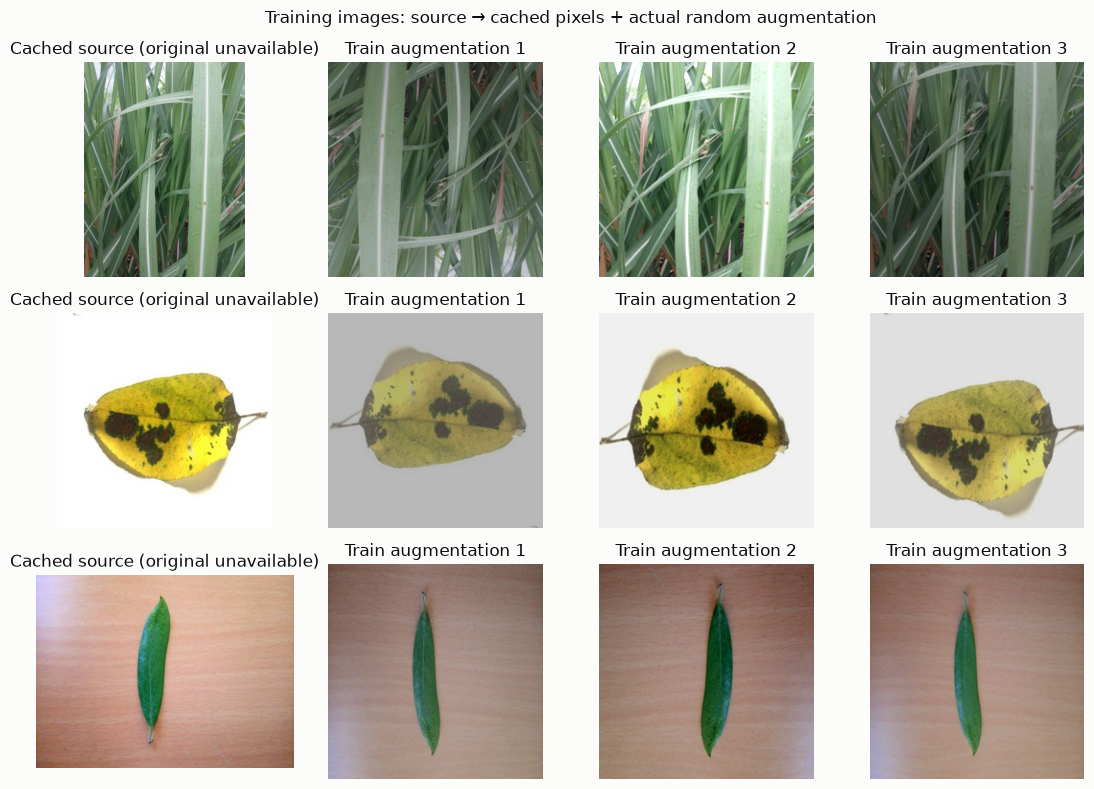

In [8]:
# Fixed light chart surface; line styles/hatches and tables carry identity without color.
COLORS = ['#2a78d6', '#eb6834', '#1baf7a']
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'text.color': '#0b0b0b', 'axes.labelcolor': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.edgecolor': '#b7b7b0', 'grid.alpha': 0.18,
                     'lines.linewidth': 2, 'font.size': 10})

def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# Actual train_tf, not a hand-written approximation. Restore RNG after preview.
preview_rng = (random.getstate(), np.random.get_state(), torch.get_rng_state())
fig, axes = plt.subplots(3, 4, figsize=(11, 8), squeeze=False)
for row, (_, example) in enumerate(dev_fit_df.sample(min(3, len(dev_fit_df)), random_state=CFG['seed']).iterrows()):
    source_path = os.path.join(SRC_IMAGES, example['file'])
    source_available = os.path.isfile(source_path)
    original = load_upright(source_path if source_available else os.path.join(IMAGE_DIR, example['file']))
    cached = load_upright(os.path.join(IMAGE_DIR, example['file']))
    axes[row, 0].imshow(original)
    axes[row, 0].set_title('Original (upright)' if source_available else 'Cached source (original unavailable)')
    for col in range(1, 4):
        augmented = train_tf(cached).permute(1, 2, 0).numpy()
        augmented = np.clip(augmented * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN), 0, 1)
        axes[row, col].imshow(augmented)
        axes[row, col].set_title(f'Train augmentation {col}')
for ax in axes.flat:
    ax.axis('off')
fig.suptitle('Training images: source → cached pixels + actual random augmentation')
save_plot(fig, 'augmentation_gallery')
random.setstate(preview_rng[0]); np.random.set_state(preview_rng[1]); torch.set_rng_state(preview_rng[2])

## 3. Independent models

In [9]:
TASKS = ('crop', 'disease')
NUM_CLASSES = {'crop': NUM_CROPS, 'disease': NUM_DISEASES}

class SingleTaskViT(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.backbone = tv_models.vit_b_16(weights=tv_models.ViT_B_16_Weights.DEFAULT)
        self.feature_dim = self.backbone.heads.head.in_features
        assert self.feature_dim == 768
        self.backbone.heads = nn.Identity()
        self.head = nn.Linear(self.feature_dim, n_classes)

    def forward(self, x):
        features = self.backbone(x)
        return self.head(features), features

def move_optimizer(optimizer, device):
    # AdamW's non-capturable step counter stays on CPU; moments follow parameters.
    for state in optimizer.state.values():
        for key, value in state.items():
            if torch.is_tensor(value):
                state[key] = value.to('cpu' if key == 'step' else device)

def offload_tasks():
    if not CFG['low_memory']:
        return
    for task in TASKS:
        models[task].zero_grad(set_to_none=True)
        models[task].to('cpu')
        if 'optimizers' in globals():
            move_optimizer(optimizers[task], 'cpu')
    if AMP:
        torch.cuda.empty_cache()

def activate_task(task, training=False):
    if CFG['low_memory']:
        offload_tasks()
        models[task].to(DEVICE)
        if training:
            move_optimizer(optimizers[task], DEVICE)

### Inference and composition scoring
Sum crop/disease log probabilities; bias only pairs absent from fit. Concatenate separately normalized 768-dimensional features.

In [10]:
@torch.no_grad()
def run_inference(models, loader):
    models.eval()
    out = {k: [] for k in ('crop_lp', 'dis_lp', 'crop_feat', 'dis_feat', 'crop', 'disease', 'comp')}
    for x, crop, disease, comp in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, fc = models['crop'](x)
            ld, fd = models['disease'](x)
        out['crop_lp'].append(F.log_softmax(lc.float(), dim=1).cpu())
        out['dis_lp'].append(F.log_softmax(ld.float(), dim=1).cpu())
        out['crop_feat'].append(fc.float().cpu()); out['dis_feat'].append(fd.float().cpu())
        out['crop'].append(crop); out['disease'].append(disease); out['comp'].append(comp)
    out = {k: torch.cat(v) for k, v in out.items()}
    assert out['crop_feat'].shape[1] == out['dis_feat'].shape[1] == 768
    out['feat'] = torch.cat([F.normalize(out['crop_feat'], dim=1), F.normalize(out['dis_feat'], dim=1)], dim=1)
    return out

def comp_scores(out):
    # score of every composition = log p(its crop) + log p(its disease)
    return out['crop_lp'][:, COMP_CROP] + out['dis_lp'][:, COMP_DIS]

def topk_acc(scores, labels, k=1, bias=0.0):
    s = scores + bias * NOVEL_MASK.float()
    return (s.topk(k, dim=1).indices == labels[:, None]).any(dim=1).float().mean().item()

def harmonic_mean(s, u):
    return 2 * s * u / (s + u) if s + u > 0 else 0.0

def bias_sweep(seen_scores, seen_labels, novel_scores, novel_labels, max_points=200):
    allsc = torch.cat([seen_scores, novel_scores])
    # gap = bias at which each sample's top prediction switches from a seen pair to a novel pair
    gap = (allsc[:, ~NOVEL_MASK].max(1).values - allsc[:, NOVEL_MASK].max(1).values).sort().values
    pick = torch.linspace(0, len(gap) - 1, min(max_points, len(gap))).long()
    biases = torch.cat([gap[:1] - 1.0, gap[pick] + 1e-4, torch.zeros(1)]).unique().tolist()
    seen = [topk_acc(seen_scores, seen_labels, 1, b) for b in biases]
    novel = [topk_acc(novel_scores, novel_labels, 1, b) for b in biases]
    hm = [harmonic_mean(s, u) for s, u in zip(seen, novel)]
    best = int(np.argmax(hm))
    order = np.argsort(seen)
    trapezoid = getattr(np, "trapezoid", None) or np.trapz   # np.trapz was renamed in NumPy 2
    auc = float(trapezoid(np.array(novel)[order], np.array(seen)[order]))
    return dict(biases=biases, seen=seen, novel=novel, hm=hm, auc=auc,
                best_bias=biases[best], best_hm=hm[best], best_seen=seen[best], best_novel=novel[best])

In [11]:
# Local inference does one deterministic loader pass per task, not GPU swaps per image.
if CFG['low_memory']:
    @torch.no_grad()
    def run_inference(models, loader):
        if not isinstance(loader.sampler, torch.utils.data.SequentialSampler):
            raise ValueError('Sequential inference requires an unshuffled evaluation loader.')
        models.eval()
        out = {}
        try:
            for task, prefix in (('crop', 'crop'), ('disease', 'dis')):
                activate_task(task)
                lp, feats, labels = [], [], []
                for x, crop, disease, comp in loader:
                    x = x.to(DEVICE, non_blocking=True)
                    with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
                        logits, features = models[task](x)
                    lp.append(F.log_softmax(logits.float(), dim=1).cpu())
                    feats.append(features.float().cpu())
                    labels.append(torch.stack((crop, disease, comp), dim=1))
                    del x, logits, features
                out[prefix + '_lp'] = torch.cat(lp)
                out[prefix + '_feat'] = torch.cat(feats)
                task_labels = torch.cat(labels)
                if task == 'crop':
                    reference_labels = task_labels
                    out.update(zip(('crop', 'disease', 'comp'), task_labels.unbind(1)))
                else:
                    assert torch.equal(reference_labels, task_labels), 'Inference label ordering changed'
                offload_tasks()
        finally:
            offload_tasks()
        assert out['crop_feat'].shape[1] == out['dis_feat'].shape[1] == 768
        out['feat'] = torch.cat([F.normalize(out['crop_feat'], dim=1), F.normalize(out['dis_feat'], dim=1)], dim=1)
        return out

## 4. Training and automatic handoff
Strict config, phase, metadata fingerprint and holdout checks protect resumable paired states. Each phase starts with freshly seeded models; previous models and optimizer owners are released first. Resume restores both models, optimizers, cosine schedules, AMP scalers, history and RNG. Final cosine horizon is the selected epoch count. Mid-epoch and cross-hardware bitwise reproducibility are not guaranteed.

In [12]:
def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if AMP else None)

def restore_rng(state):
    random.setstate(state['python']); np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'].cpu())
    if AMP and state['cuda'] is not None:
        torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda']])

def atomic_save(state, path):
    torch.save(state, path + '.tmp')
    os.replace(path + '.tmp', path)



### Shared epoch implementation
Each task uses only its own summed cross-entropy, divided by actual accumulated examples (including the last partial window). No test evaluation occurs here.

In [13]:
def train_one_epoch(epoch):
    models.train()
    loss_sum, hits = {t: 0.0 for t in TASKS}, {t: 0 for t in TASKS}
    groups = [(t,) for t in TASKS] if CFG['low_memory'] else [TASKS]
    try:
        for active_tasks in groups:
            if CFG['low_memory']:
                activate_task(active_tasks[0], training=True)
                # Repeat order and CPU augmentation RNG for both independent tasks.
                # Current ViT has no stochastic CPU forward operations or dropout.
                epoch_seed = CFG['seed'] + epoch
                seed_everything(epoch_seed)
                train_generator.manual_seed(epoch_seed)
            n, window_n = 0, 0
            for t in active_tasks:
                optimizers[t].zero_grad(set_to_none=True)
            task_label = '+'.join(active_tasks)
            progress = tqdm(train_loader, desc=f"epoch {epoch+1}/{EPOCHS} {task_label}",
                            unit='batch', leave=False, dynamic_ncols=True)
            for step, (x, crop, disease, _) in enumerate(progress):
                x = x.to(DEVICE, non_blocking=True)
                targets = {'crop': crop.to(DEVICE), 'disease': disease.to(DEVICE)}
                for t in active_tasks:
                    with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
                        logits, features = models[t](x)
                        loss = criterion(logits, targets[t])
                    scalers[t].scale(loss).backward()
                    loss_sum[t] += loss.detach().item()
                    hits[t] += (logits.detach().argmax(1) == targets[t]).sum().item()
                    del logits, features, loss
                n += len(x)
                window_n += len(x)
                if (step + 1) % CFG['accumulation_steps'] == 0 or step + 1 == len(train_loader):
                    for t in active_tasks:
                        scalers[t].unscale_(optimizers[t])
                        for p in models[t].parameters():
                            if p.grad is not None:
                                p.grad.div_(window_n)
                        scalers[t].step(optimizers[t])
                        scalers[t].update()
                        optimizers[t].zero_grad(set_to_none=True)
                    window_n = 0
                if (step + 1) % 10 == 0 or step + 1 == len(train_loader):
                    progress.set_postfix({t: f"{loss_sum[t] / max(n, 1):.3f}" for t in active_tasks})
                del x, targets
            assert n == len(fit_df) and window_n == 0
            offload_tasks()
    finally:
        offload_tasks()
    return dict(train_crop_loss=loss_sum['crop'] / n, train_disease_loss=loss_sum['disease'] / n,
                train_crop_acc=hits['crop'] / n, train_disease_acc=hits['disease'] / n)

def validate():
    vs, vu = run_inference(models, val_seen_loader), run_inference(models, val_unseen_loader)
    S_, U_ = comp_scores(vs), comp_scores(vu)
    sweep = bias_sweep(S_, vs['comp'], U_, vu['comp'])
    return dict(
        val_seen_top1_b0=topk_acc(S_, vs['comp']), val_unseen_top1_b0=topk_acc(U_, vu['comp']),
        val_seen_at_best=sweep['best_seen'], val_unseen_at_best=sweep['best_novel'],
        val_best_hm=sweep['best_hm'], val_best_bias=sweep['best_bias'], val_auc=sweep['auc'],
        val_unseen_crop_acc=(vu['crop_lp'].argmax(1) == vu['crop']).float().mean().item(),
        val_unseen_disease_acc=(vu['dis_lp'].argmax(1) == vu['disease']).float().mean().item(),
    )



### Run dev, then fresh final training
Each checkpoint contains paired crop/disease state. Final uses the dev-selected epochs and bias. Resume is epoch-boundary only; load only trusted checkpoints.

In [14]:
def release_training_state():
    for name in ('models', 'optimizers', 'schedulers', 'scalers', 'criterion'):
        globals().pop(name, None)
    gc.collect()
    if AMP:
        torch.cuda.empty_cache()

def run_phase(phase, selection=None):
    global models, optimizers, schedulers, scalers, criterion, fit_df, NOVEL_MASK
    global train_loader, val_seen_loader, val_unseen_loader, train_generator
    global EPOCHS, DEV_BIAS, BEST_CKPT
    release_training_state()
    seed_everything(CFG['seed'])
    EPOCHS = CFG['epochs'] if phase == 'dev' else selection['best_epoch']
    DEV_BIAS = None if phase == 'dev' else selection['best_bias']
    dev_selection = None if phase == 'dev' else dict(best_epoch=EPOCHS, best_bias=DEV_BIAS)
    assert phase in ('dev', 'final') and 1 <= EPOCHS <= CFG['epochs']
    assert DEV_BIAS is None or math.isfinite(DEV_BIAS)
    fit_df = dev_fit_df if phase == 'dev' else train_df
    NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
    NOVEL_MASK[sorted(set(fit_df['comp']))] = False
    train_loader = make_loader(fit_df, train=True)
    val_seen_loader = make_loader(val_seen_df, train=False)
    val_unseen_loader = make_loader(val_unseen_df, train=False)
    train_generator = torch.Generator() if CFG['low_memory'] else None
    if train_generator is not None:
        train_loader.generator = train_generator
        train_loader.sampler.generator = train_generator
    last_path = os.path.join(OUT_DIR, phase + '_last.pt')
    BEST_CKPT = os.path.join(OUT_DIR, phase + '_best.pt')
    history_path = os.path.join(OUT_DIR, phase + '_history.csv')
    expected = dict(cfg=CFG, epochs=EPOCHS, protocol=PROTOCOL, phase=phase,
                    data_fingerprint=DATA_FINGERPRINT, dev_selection=dev_selection, holdout_ids=HOLDOUT)
    ck = None
    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location='cpu', weights_only=False)
        if any(ck.get(k) != v for k, v in expected.items()):
            raise RuntimeError(f'Incompatible {phase} checkpoint. Preserve runs before changing configuration.')
    elif os.path.exists(BEST_CKPT):
        raise RuntimeError(f'{phase}_best.pt exists without last checkpoint; preserve/recover the interrupted run.')
    models = nn.ModuleDict({t: SingleTaskViT(NUM_CLASSES[t]) for t in TASKS}).to('cpu' if CFG['low_memory'] else DEVICE)
    assert not ({id(p) for p in models['crop'].parameters()} & {id(p) for p in models['disease'].parameters()})
    optimizers = {t: torch.optim.AdamW(models[t].parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay']) for t in TASKS}
    schedulers = {t: torch.optim.lr_scheduler.CosineAnnealingLR(optimizers[t], T_max=EPOCHS) for t in TASKS}
    scalers = {t: torch.amp.GradScaler('cuda', enabled=AMP) for t in TASKS}
    criterion = nn.CrossEntropyLoss(reduction='sum')
    start_epoch, history, best_hm = 0, [], -1.0
    if ck is not None:
        models.load_state_dict(ck['models'])
        for t in TASKS:
            optimizers[t].load_state_dict(ck['optimizers'][t])
            schedulers[t].load_state_dict(ck['schedulers'][t])
            scalers[t].load_state_dict(ck['scalers'][t])
        start_epoch, history, best_hm = ck['epoch'], ck['history'], ck['best_hm']
        assert 0 <= start_epoch <= EPOCHS and len(history) == start_epoch
        restore_rng(ck['rng'])
        del ck
        print(f"{phase}: resumed after epoch {start_epoch}/{EPOCHS}; next epoch {start_epoch + 1}", flush=True)
    offload_tasks()
    if phase == 'dev' and history:
        chosen = max(history, key=lambda row: row['val_best_hm'])
        if chosen['epoch'] == start_epoch:
            atomic_save(dict(models=models.state_dict(), epoch=start_epoch,
                             bias=chosen['val_best_bias'], **expected), BEST_CKPT)
        else:
            paired = torch.load(BEST_CKPT, map_location='cpu', weights_only=False)
            if (any(paired.get(k) != v for k, v in expected.items())
                    or paired['epoch'] != chosen['epoch'] or paired['bias'] != chosen['val_best_bias']):
                raise RuntimeError('Dev best/last mismatch; preserve files for recovery.')
            paired = None
    print(f"{phase}: {EPOCHS} epochs | {len(train_loader)} batches/epoch | "
          f"microbatch {CFG['batch_size']} x accumulation {CFG['accumulation_steps']} "
          f"(effective {CFG['batch_size'] * CFG['accumulation_steps']})", flush=True)
    for epoch in range(start_epoch, EPOCHS):
        t0 = time.time()
        print(f"\n{phase} epoch {epoch + 1}/{EPOCHS} started", flush=True)
        row = dict(epoch=epoch + 1, **train_one_epoch(epoch))
        for t in TASKS:
            row[t + '_lr'] = optimizers[t].param_groups[0]['lr']
            schedulers[t].step()
        improved = False
        if phase == 'dev':
            row.update(validate())
            improved = row['val_best_hm'] > best_hm
            if improved:
                best_hm = row['val_best_hm']
        row['seconds'] = round(time.time() - t0, 1)
        history.append(row)
        print(f"{phase} epoch {epoch + 1}/{EPOCHS} done in {row['seconds']}s | "
              f"crop loss {row['train_crop_loss']:.4f} acc {row['train_crop_acc']:.4f} | "
              f"disease loss {row['train_disease_loss']:.4f} acc {row['train_disease_acc']:.4f}", flush=True)
        if phase == 'dev':
            print(f"  val seen {row['val_seen_at_best']:.4f} | unseen {row['val_unseen_at_best']:.4f} | "
                  f"HM {row['val_best_hm']:.4f} | bias {row['val_best_bias']:.4f} | AUC {row['val_auc']:.4f}", flush=True)
        offload_tasks()
        # Save last first. If interrupted before best, resume can repair best from last.
        atomic_save(dict(models=models.state_dict(),
                         optimizers={t: o.state_dict() for t, o in optimizers.items()},
                         schedulers={t: s.state_dict() for t, s in schedulers.items()},
                         scalers={t: s.state_dict() for t, s in scalers.items()}, rng=rng_state(),
                         epoch=epoch + 1, history=history, best_hm=best_hm, **expected), last_path)
        print(f"  saved {os.path.basename(last_path)}", flush=True)
        if improved:
            atomic_save(dict(models=models.state_dict(), epoch=epoch + 1,
                             bias=row['val_best_bias'], **expected), BEST_CKPT)
            print(f"  saved {os.path.basename(BEST_CKPT)} (best HM {row['val_best_hm']:.4f} @ epoch {epoch + 1})", flush=True)
        pd.DataFrame(history).to_csv(history_path, index=False)
        print(f"  history {os.path.basename(history_path)}", flush=True)
    pd.DataFrame(history).to_csv(history_path, index=False)
    if phase == 'final':
        atomic_save(dict(models=models.state_dict(), epoch=EPOCHS, bias=DEV_BIAS, **expected), BEST_CKPT)
        return selection
    chosen = max(history, key=lambda row: row['val_best_hm'])
    if chosen['epoch'] == EPOCHS:
        atomic_save(dict(models=models.state_dict(), epoch=EPOCHS, bias=chosen['val_best_bias'], **expected), BEST_CKPT)
    best = torch.load(BEST_CKPT, map_location='cpu', weights_only=False)
    if (any(best.get(k) != v for k, v in expected.items()) or best['epoch'] != chosen['epoch']
            or best['bias'] != chosen['val_best_bias']):
        raise RuntimeError('Dev best/last disagree; preserve interrupted files for recovery.')
    summary = dict(best_epoch=best['epoch'], best_bias=best['bias'], val_best_hm=best_hm, **expected)
    del best
    with open(DEV_SUMMARY + '.tmp', 'w') as f:
        json.dump(summary, f, indent=2)
    os.replace(DEV_SUMMARY + '.tmp', DEV_SUMMARY)
    return summary

selection = None
for phase in ('dev', 'final'):
    print('Starting', phase)
    selection = run_phase(phase, selection)
print('Final paired checkpoint ready; test evaluation follows.')

Starting dev
dev: 20 epochs | 1739 batches/epoch | microbatch 4 x accumulation 8 (effective 32)

dev epoch 1/20 started


dev epoch 1/20 done in 359.9s | crop loss 1.1656 acc 0.7421 | disease loss 2.6534 acc 0.4481
  val seen 0.6599 | unseen 0.5961 | HM 0.6263 | bias 2.5938 | AUC 0.5020
  saved dev_last.pt
  saved dev_best.pt (best HM 0.6263 @ epoch 1)
  history dev_history.csv

dev epoch 2/20 started


dev epoch 2/20 done in 381.1s | crop loss 0.3319 acc 0.9316 | disease loss 1.3340 acc 0.7128
  val seen 0.6458 | unseen 0.7414 | HM 0.6903 | bias 5.1041 | AUC 0.6178
  saved dev_last.pt
  saved dev_best.pt (best HM 0.6903 @ epoch 2)
  history dev_history.csv

dev epoch 3/20 started


dev epoch 3/20 done in 388.6s | crop loss 0.1757 acc 0.9682 | disease loss 0.8964 acc 0.8072
  val seen 0.7602 | unseen 0.6084 | HM 0.6759 | bias 4.3014 | AUC 0.5323
  saved dev_last.pt
  history dev_history.csv

dev epoch 4/20 started


dev epoch 4/20 done in 365.3s | crop loss 0.1105 acc 0.9781 | disease loss 0.6572 acc 0.8557
  val seen 0.7696 | unseen 0.6527 | HM 0.7063 | bias 5.4757 | AUC 0.6018
  saved dev_last.pt
  saved dev_best.pt (best HM 0.7063 @ epoch 4)
  history dev_history.csv

dev epoch 5/20 started


dev epoch 5/20 done in 377.0s | crop loss 0.0648 acc 0.9909 | disease loss 0.4730 acc 0.8981
  val seen 0.7053 | unseen 0.7266 | HM 0.7158 | bias 6.6656 | AUC 0.6259
  saved dev_last.pt
  saved dev_best.pt (best HM 0.7158 @ epoch 5)
  history dev_history.csv

dev epoch 6/20 started


... (21 outputs left out)

final epoch 7/10 done in 577.5s | crop loss 0.0183 acc 0.9995 | disease loss 0.2238 acc 0.9625
  saved final_last.pt
  history final_history.csv

final epoch 8/10 started


final epoch 8/10 done in 527.4s | crop loss 0.0145 acc 0.9995 | disease loss 0.1799 acc 0.9751
  saved final_last.pt
  history final_history.csv

final epoch 9/10 started


final epoch 9/10 done in 525.6s | crop loss 0.0116 acc 0.9999 | disease loss 0.1477 acc 0.9812
  saved final_last.pt
  history final_history.csv

final epoch 10/10 started


final epoch 10/10 done in 598.6s | crop loss 0.0107 acc 1.0000 | disease loss 0.1365 acc 0.9848
  saved final_last.pt
  history final_history.csv
Final paired checkpoint ready; test evaluation follows.


,epoch,train_crop_loss,train_disease_loss,train_crop_acc,train_disease_acc,crop_lr,disease_lr,val_seen_top1_b0,val_unseen_top1_b0,val_seen_at_best,val_unseen_at_best,val_best_hm,val_best_bias,val_auc,val_unseen_crop_acc,val_unseen_disease_acc,seconds
0,1,1.165618,2.653424,0.742093,0.448102,3.000000e-05,3.000000e-05,0.703762,0.423645,0.659875,0.596059,0.626346,2.593850,0.501986,0.830049,0.435961,359.9
1,2,0.331923,1.334013,0.931570,0.712766,2.981533e-05,2.981533e-05,0.793103,0.423645,0.645768,0.741379,0.690279,5.104105,0.617821,0.775862,0.495074,381.1
2,3,0.175726,0.896404,0.968229,0.807217,2.926585e-05,2.926585e-05,0.808777,0.302956,0.760188,0.608374,0.675861,4.301370,0.532284,0.857143,0.285714,388.6
3,4,0.110462,0.657228,0.978148,0.855664,2.836510e-05,2.836510e-05,0.840125,0.278325,0.769592,0.652709,0.706348,5.475686,0.601819,0.862069,0.285714,365.3
4,5,0.064766,0.472995,0.990943,0.898074,2.713525e-05,2.713525e-05,0.847962,0.169951,0.705329,0.726601,0.715807,6.665627,0.625890,0.859606,0.184729,377.0
5,6,0.037969,0.333369,0.996118,0.933295,2.560660e-05,2.560660e-05,0.851097,0.177340,0.764890,0.711823,0.737403,6.426858,0.654638,0.866995,0.169951,360.9
6,7,0.025553,0.263040,0.997987,0.948821,2.381678e-05,2.381678e-05,0.852665,0.165025,0.755486,0.741379,0.748366,6.812111,0.690983,0.871921,0.165025,363.5
7,8,0.016347,0.175242,0.998994,0.971392,2.180986e-05,2.180986e-05,0.866771,0.182266,0.768025,0.711823,0.738857,6.982522,0.652478,0.876847,0.182266,354.5
8,9,0.010015,0.137332,0.999425,0.980736,1.963525e-05,1.963525e-05,0.866771,0.238916,0.749216,0.768473,0.758722,7.176858,0.695157,0.876847,0.241379,674.8
9,10,0.010042,0.116478,0.999281,0.984330,1.734652e-05,1.734652e-05,0.862069,0.231527,0.782132,0.753695,0.767650,6.778604,0.686939,0.864532,0.229064,559.8


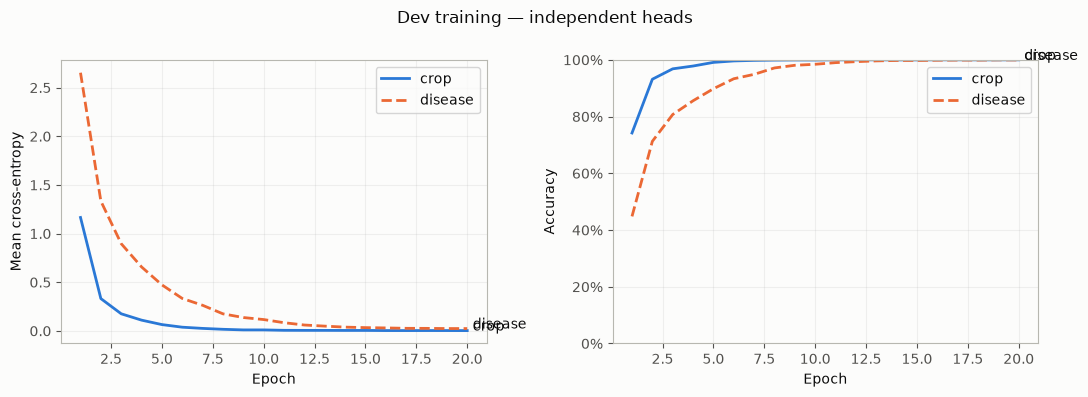

,epoch,train_crop_loss,train_disease_loss,train_crop_acc,train_disease_acc,crop_lr,disease_lr,seconds
0,1,1.065231,2.497767,0.764875,0.482625,3.000000e-05,3.000000e-05,444.5
1,2,0.296422,1.241831,0.938875,0.728125,2.926585e-05,2.926585e-05,501.0
2,3,0.160650,0.834039,0.967750,0.818875,2.713525e-05,2.713525e-05,525.0
3,4,0.094116,0.577969,0.982000,0.873250,2.381678e-05,2.381678e-05,491.8
4,5,0.054604,0.414774,0.991875,0.913375,1.963525e-05,1.963525e-05,623.8
5,6,0.030520,0.307887,0.998125,0.942250,1.500000e-05,1.500000e-05,589.7
6,7,0.018346,0.223784,0.999500,0.962500,1.036475e-05,1.036475e-05,577.5
7,8,0.014451,0.179872,0.999500,0.975125,6.183221e-06,6.183221e-06,527.4
8,9,0.011588,0.147684,0.999875,0.981250,2.864745e-06,2.864745e-06,525.6
9,10,0.010685,0.136528,1.000000,0.984750,7.341523e-07,7.341523e-07,598.6


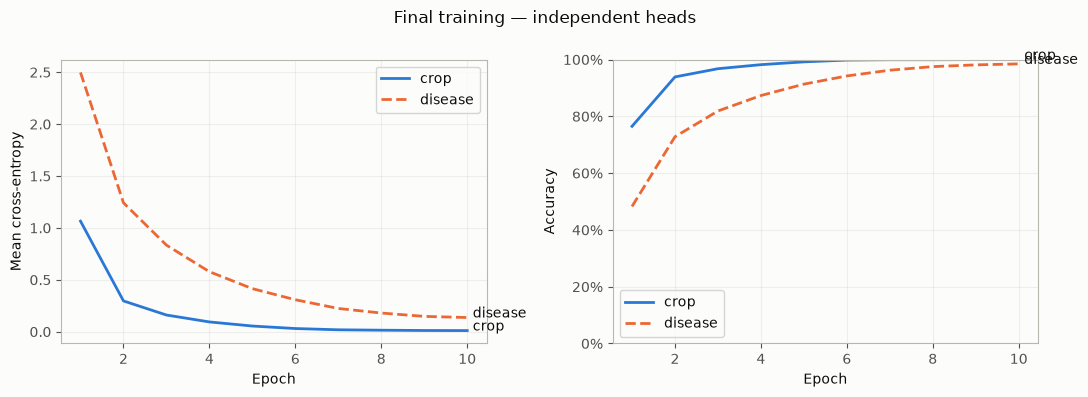

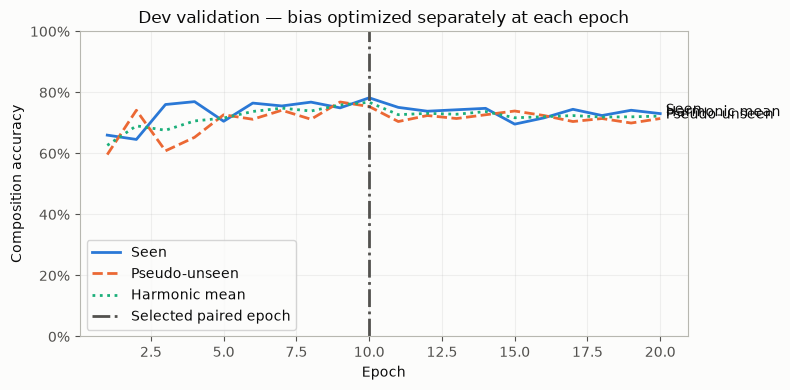

In [15]:
for phase_name in ('dev', 'final'):
    table = pd.read_csv(os.path.join(OUT_DIR, phase_name + '_history.csv'))
    display(table)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for task, color, style in zip(TASKS, COLORS, ('-', '--')):
        for ax, metric in zip(axes, ('loss', 'acc')):
            values = table[f'train_{task}_{metric}']
            ax.plot(table['epoch'], values, color=color, linestyle=style, label=task)
            ax.annotate(task, (table['epoch'].iloc[-1], values.iloc[-1]), xytext=(4, 0), textcoords='offset points')
            ax.set(xlabel='Epoch', ylabel='Mean cross-entropy' if metric == 'loss' else 'Accuracy')
            ax.grid(True); ax.legend()
    axes[1].set_ylim(0, 1); axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    fig.suptitle(f'{phase_name.title()} training — independent heads')
    save_plot(fig, phase_name + '_training_curves')

dev_history = pd.read_csv(os.path.join(OUT_DIR, 'dev_history.csv'))
fig, ax = plt.subplots(figsize=(8, 4))
for column, label, color, style in zip(
        ('val_seen_at_best', 'val_unseen_at_best', 'val_best_hm'),
        ('Seen', 'Pseudo-unseen', 'Harmonic mean'), COLORS, ('-', '--', ':')):
    ax.plot(dev_history['epoch'], dev_history[column], color=color, linestyle=style, label=label)
    ax.annotate(label, (dev_history['epoch'].iloc[-1], dev_history[column].iloc[-1]), xytext=(4, 0), textcoords='offset points')
ax.axvline(selection['best_epoch'], color='#52514e', linestyle='-.', label='Selected paired epoch')
ax.set(xlabel='Epoch', ylabel='Composition accuracy', ylim=(0, 1),
       title='Dev validation — bias optimized separately at each epoch')
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.grid(True); ax.legend()
save_plot(fig, 'dev_validation_curves')

## 5. Evaluation and visualizations
Reported results use the fixed dev bias. The test sweep provides AUC and an explicitly labeled oracle upper bound only; it never changes model selection or reported bias.

In [16]:
assert phase == 'final' and DEV_BIAS is not None
models.load_state_dict(torch.load(BEST_CKPT, map_location='cpu', weights_only=False)['models'])
ts = run_inference(models, make_loader(test_seen_df, train=False))
tu = run_inference(models, make_loader(test_unseen_df, train=False))
S_test, U_test = comp_scores(ts), comp_scores(tu)
test_sweep = bias_sweep(S_test, ts['comp'], U_test, tu['comp'])

def report(bias):
    s1, u1 = topk_acc(S_test, ts['comp'], 1, bias), topk_acc(U_test, tu['comp'], 1, bias)
    return {'bias': round(bias, 3), 'seen top-1': s1, 'seen top-5': topk_acc(S_test, ts['comp'], 5, bias),
            'unseen top-1': u1, 'unseen top-5': topk_acc(U_test, tu['comp'], 5, bias),
            'harmonic mean': harmonic_mean(s1, u1)}

results = pd.DataFrame({
    'b = 0 (no calibration)': report(0.0),
    'b from dev validation (REPORTED)': report(DEV_BIAS),
    'oracle b on test (upper bound)': report(test_sweep['best_bias']),
}).T
display(results.style.format({c: '{:.2%}' for c in results.columns if c != 'bias'}))
print(f"seen/unseen AUC: {test_sweep['auc']:.4f}")

,bias,seen top-1,seen top-5,unseen top-1,unseen top-5,harmonic mean
b = 0 (no calibration),0.000000,67.55%,87.85%,10.15%,37.71%,17.65%
b from dev validation (REPORTED),6.779000,59.70%,84.40%,65.81%,92.75%,62.61%
oracle b on test (upper bound),7.913000,55.95%,82.85%,74.52%,93.99%,63.91%


seen/unseen AUC: 0.5114


### Independent argmax results
No valid-pair filtering or bias. Joint accuracy requires both heads correct; this differs from composition-ranked metrics.

In [17]:
def paper_protocol(out):
    pc, pdis = out['crop_lp'].argmax(1), out['dis_lp'].argmax(1)
    return {'crop acc': (pc == out['crop']).float().mean().item(),
            'disease acc': (pdis == out['disease']).float().mean().item(),
            'crop+disease acc': ((pc == out['crop']) & (pdis == out['disease'])).float().mean().item()}

head_table = pd.DataFrame({'test-seen': paper_protocol(ts), 'test-unseen': paper_protocol(tu)}).T
display(head_table.style.format('{:.2%}'))
PAPER_HM = harmonic_mean(head_table.at['test-seen', 'crop+disease acc'], head_table.at['test-unseen', 'crop+disease acc'])
print(f'independent-argmax harmonic mean: {PAPER_HM:.2%}')

train_pairs = set(zip(fit_df['crop'], fit_df['disease']))
pred_dis = tu['dis_lp'].argmax(1)
wrong = pred_dis != tu['disease']
shortcut = [(int(c), int(d)) in train_pairs for c, d in zip(tu['crop'][wrong], pred_dis[wrong])]
SHORTCUT_RATE = float(np.mean(shortcut)) if shortcut else 0.0
print(f'unseen images with the wrong disease: {int(wrong.sum())}/{len(wrong)}')
print(f'shortcut rate (wrong disease is one the true crop had in training): {SHORTCUT_RATE:.2%}')

,crop acc,disease acc,crop+disease acc
test-seen,90.05%,68.90%,65.95%
test-unseen,70.93%,11.60%,7.25%


independent-argmax harmonic mean: 13.07%
unseen images with the wrong disease: 1280/1448
shortcut rate (wrong disease is one the true crop had in training): 59.30%


### Save metrics and inspect errors
All tables and PNG plots use the same runs folder. Confusion matrices show frequent-label subsets with an Other column; full counts are exported. Optional feature export and bounded t-SNE are disabled by default.

In [18]:
metrics = dict(model='Baseline 1: independent ViT-B/16 (crop + disease)', epochs=EPOCHS,
               dev_bias=DEV_BIAS, results=results.to_dict(orient='index'), auc=test_sweep['auc'],
               heads=head_table.to_dict(orient='index'), paper_protocol_hm=PAPER_HM,
               shortcut_rate=SHORTCUT_RATE, cfg=CFG, protocol=PROTOCOL, data_fingerprint=DATA_FINGERPRINT)
with open(os.path.join(OUT_DIR, 'metrics.json'), 'w') as f:
    json.dump(metrics, f, indent=2)
EXPORT_FEATURE_BANK = False
if EXPORT_FEATURE_BANK:
    bank = run_inference(models, make_loader(fit_df, train=False))
    bank_feats = F.normalize(bank['feat'], dim=1)
    assert bank_feats.shape[1] == 1536
    np.savez_compressed(os.path.join(OUT_DIR, 'feature_bank.npz'),
                        feats=bank_feats.numpy().astype(np.float16), files=fit_df['file'].values,
                        comp=bank['comp'].numpy(), crop=bank['crop'].numpy(), disease=bank['disease'].numpy())
print('saved metrics to', OUT_DIR)

saved metrics to C:\Users\basil\Documents\001_Year4_Sem7(Extended)\COS30082 APPLIED MACHINE LEARNING\Group_ML Assignment\COS30082-ML-Project\Baseline1\ViT Backbone\runs


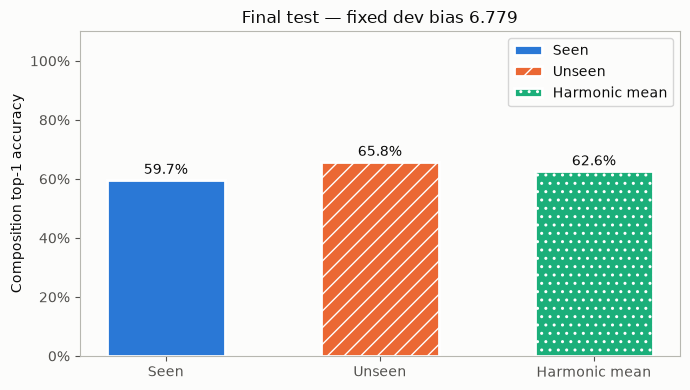

,biases,seen,novel,hm
0,-8.358398,0.6770,0.000000,0.000000
1,-7.358298,0.6770,0.000691,0.001380
2,-5.636619,0.6770,0.012431,0.024414
3,-4.603415,0.6770,0.024171,0.046676
4,-3.432517,0.6770,0.035912,0.068205
...,...,...,...,...
197,20.330908,0.0350,0.801105,0.067070
198,20.589149,0.0260,0.801105,0.050365
199,20.941505,0.0175,0.801105,0.034252
200,21.300148,0.0090,0.801105,0.017800


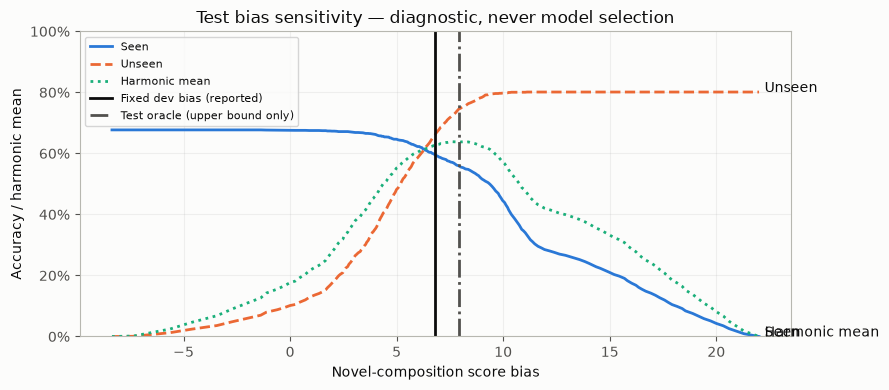

,tomato,grape,cassava,corn,apple,pepper_bell,paddy,mango,cotton,sugarcane,cherry,cucumber,Other predictions
tomato,700,1,2,0,12,2,0,0,0,0,0,1,45
grape,6,207,1,0,6,1,0,10,4,0,0,3,74
cassava,0,0,267,0,0,0,0,0,0,0,0,0,2
corn,0,0,4,232,0,0,1,0,0,0,0,0,4
apple,1,0,2,0,220,0,0,0,1,0,0,0,14
pepper_bell,44,0,1,1,3,140,0,0,2,0,0,0,39
paddy,0,0,0,1,0,0,152,0,0,1,0,0,4
mango,0,0,2,0,1,0,0,134,0,0,0,0,11
cotton,15,5,8,0,6,0,0,1,89,0,0,1,19
sugarcane,0,0,0,9,0,0,0,0,0,116,0,0,8


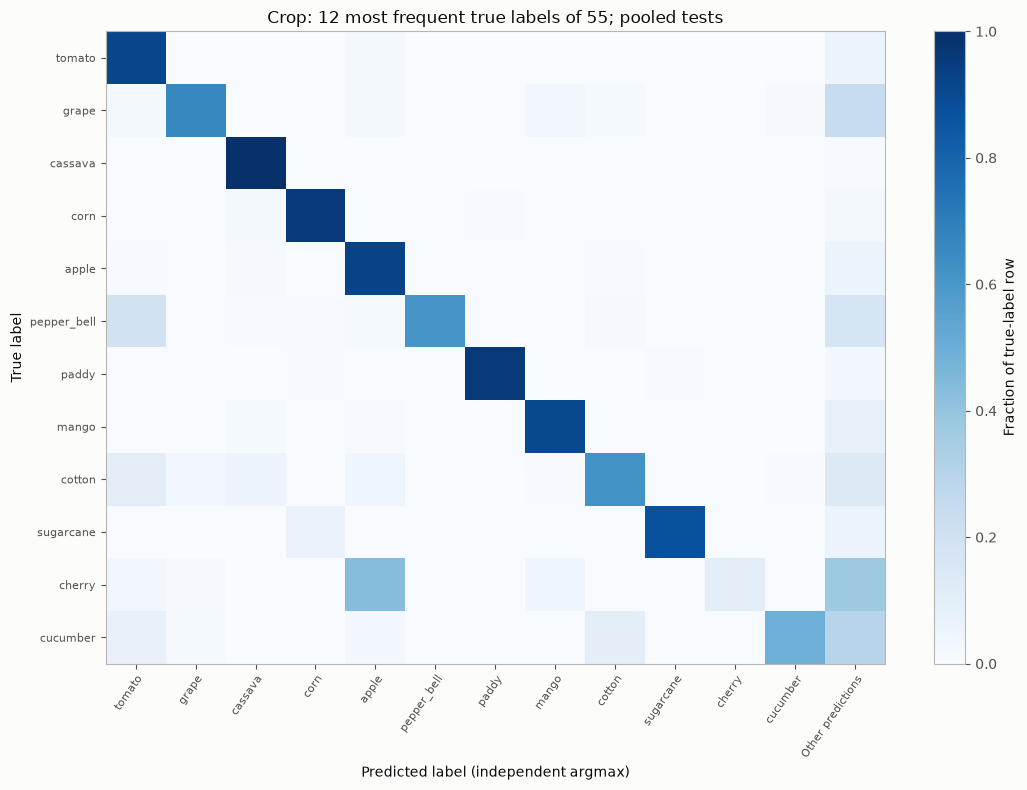

,early_blight,healthy,black_rot,bacterial_spot,rust,bacterial_blight,mosaic,anthracnose,brown_spot,powdery_mildew,aphis_spp,streak_virus,Other predictions
early_blight,22,1,5,58,12,6,3,14,14,2,2,0,358
healthy,0,259,0,1,0,5,4,0,3,1,0,0,80
black_rot,0,5,6,2,2,0,0,22,0,2,0,0,248
bacterial_spot,0,9,1,127,7,2,0,4,0,3,0,0,119
rust,0,6,0,0,81,2,11,0,5,0,0,2,66
bacterial_blight,0,11,1,7,0,17,2,13,5,6,0,0,94
mosaic,0,11,0,0,0,1,110,0,0,0,0,0,8
anthracnose,0,1,0,0,1,0,1,11,41,0,0,0,55
brown_spot,0,1,0,0,1,5,1,0,52,0,0,5,42
powdery_mildew,0,2,0,0,2,0,0,1,0,78,0,0,6


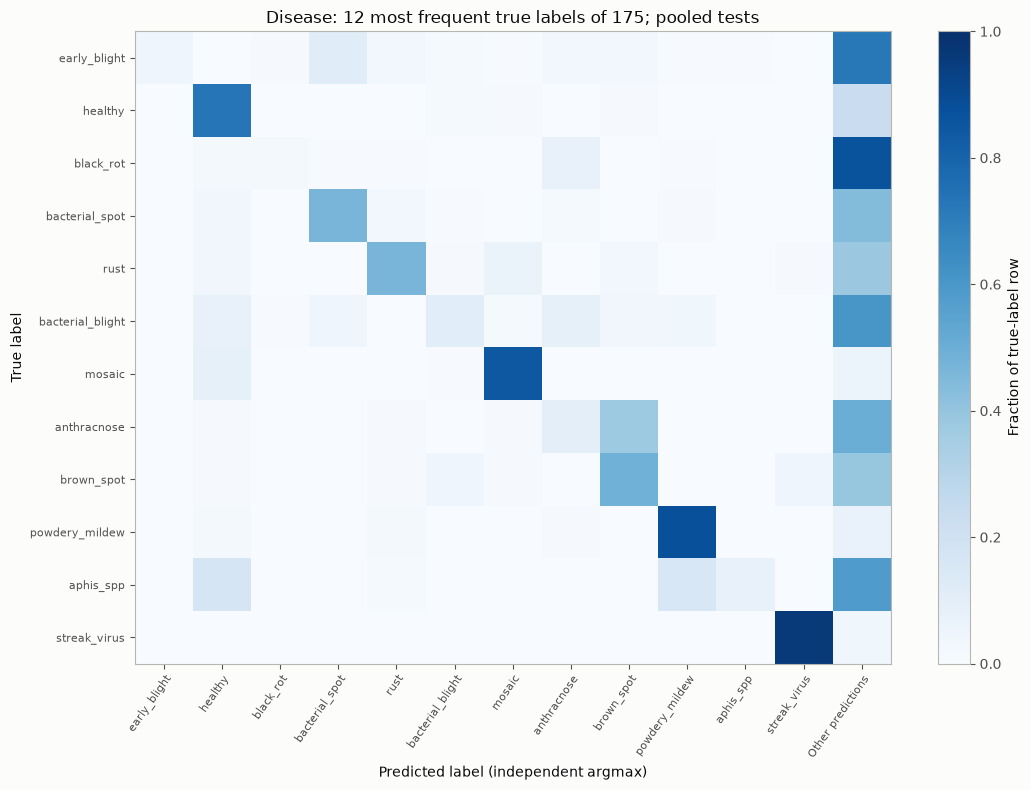

In [19]:
reported = results.loc['b from dev validation (REPORTED)']
fig, ax = plt.subplots(figsize=(7, 4))
labels = ['Seen', 'Unseen', 'Harmonic mean']
values = [reported['seen top-1'], reported['unseen top-1'], reported['harmonic mean']]
for i, (label, value, color, hatch) in enumerate(zip(labels, values, COLORS, ('', '//', '..'))):
    ax.bar(i, value, width=0.55, color=color, edgecolor='white', linewidth=2, hatch=hatch, label=label)
    ax.text(i, value + 0.02, f'{value:.1%}', ha='center')
ax.set(xticks=range(3), xticklabels=labels, ylim=(0, 1.1), ylabel='Composition top-1 accuracy',
       title=f'Final test — fixed dev bias {DEV_BIAS:.3f}')
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend()
save_plot(fig, 'final_calibrated_accuracy')

tradeoff = pd.DataFrame({key: test_sweep[key] for key in ('biases', 'seen', 'novel', 'hm')}).sort_values('biases')
tradeoff.to_csv(os.path.join(OUT_DIR, 'test_bias_tradeoff.csv'), index=False)
display(tradeoff)
fig, ax = plt.subplots(figsize=(9, 4))
for key, label, color, style in zip(('seen', 'novel', 'hm'), labels, COLORS, ('-', '--', ':')):
    ax.plot(tradeoff['biases'], tradeoff[key], color=color, linestyle=style, label=label)
    ax.annotate(label, (tradeoff['biases'].iloc[-1], tradeoff[key].iloc[-1]), xytext=(4, 0), textcoords='offset points')
ax.axvline(DEV_BIAS, color='#0b0b0b', linestyle='-', label='Fixed dev bias (reported)')
ax.axvline(test_sweep['best_bias'], color='#52514e', linestyle='-.', label='Test oracle (upper bound only)')
ax.set(xlabel='Novel-composition score bias', ylabel='Accuracy / harmonic mean', ylim=(0, 1),
       title='Test bias sensitivity — diagnostic, never model selection')
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.grid(True); ax.legend(fontsize=8)
save_plot(fig, 'final_bias_tradeoff')

# Independent argmax heads, pooled seen + unseen. Show frequent true-label rows and
# preserve all remaining predictions in Other so row totals are never hidden.
for task, lp_key, name_key, n_classes in (
        ('crop', 'crop_lp', 'crop_name', NUM_CROPS),
        ('disease', 'dis_lp', 'disease_name', NUM_DISEASES)):
    truth = torch.cat([ts[task], tu[task]]).numpy()
    pred = torch.cat([ts[lp_key], tu[lp_key]]).argmax(1).numpy()
    names = all_df.drop_duplicates(task).set_index(task)[name_key].to_dict()
    full = confusion_matrix(truth, pred, labels=np.arange(n_classes))
    pd.DataFrame(full, index=[names.get(i, str(i)) for i in range(n_classes)],
                 columns=[names.get(i, str(i)) for i in range(n_classes)]).to_csv(os.path.join(OUT_DIR, task + '_confusion_counts.csv'))
    keep = np.argsort(-full.sum(1), kind='stable')[:min(12, n_classes)]
    subset = full[np.ix_(keep, keep)]
    other = full[keep].sum(1) - subset.sum(1)
    shown = np.column_stack([subset, other])
    normalized = shown / np.maximum(shown.sum(1, keepdims=True), 1)
    row_names = [str(names.get(int(i), i)) for i in keep]
    column_names = row_names + ['Other predictions']
    display(pd.DataFrame(shown, index=row_names, columns=column_names))
    fig, ax = plt.subplots(figsize=(11, 8))
    image = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set(xticks=np.arange(len(column_names)), xticklabels=column_names,
           yticks=np.arange(len(row_names)), yticklabels=row_names,
           xlabel='Predicted label (independent argmax)', ylabel='True label',
           title=f'{task.title()}: {len(keep)} most frequent true labels of {n_classes}; pooled tests')
    plt.setp(ax.get_xticklabels(), rotation=55, ha='right', rotation_mode='anchor', fontsize=8)
    ax.tick_params(axis='y', labelsize=8)
    fig.colorbar(image, ax=ax, label='Fraction of true-label row')
    save_plot(fig, task + '_confusion_matrix')

RUN_TSNE = False  # optional: at most 600 existing test features, no extra model pass
if RUN_TSNE:
    from sklearn.manifold import TSNE
    features = torch.cat([ts['feat'], tu['feat']]).numpy()
    indices = np.random.default_rng(CFG['seed']).choice(len(features), min(600, len(features)), replace=False)
    if len(indices) >= 5:
        embedding = TSNE(n_components=2, perplexity=min(30, len(indices) - 1),
                         init='pca', learning_rate='auto', random_state=CFG['seed']).fit_transform(features[indices])
        for task in TASKS:
            y = torch.cat([ts[task], tu[task]]).numpy()[indices]
            selected_labels = pd.Series(y).value_counts().index[:3]
            fig, axes = plt.subplots(1, len(selected_labels), figsize=(12, 4), squeeze=False)
            name_key = task + '_name'
            names = all_df.drop_duplicates(task).set_index(task)[name_key].to_dict()
            for ax, label in zip(axes.flat, selected_labels):
                ax.scatter(embedding[:, 0], embedding[:, 1], color='#b7b7b0', s=12, label='Other labels')
                mask = y == label
                ax.scatter(embedding[mask, 0], embedding[mask, 1], color=COLORS[0], s=25, marker='x', label='Selected label')
                ax.set(title=str(names.get(label, label)), xlabel='t-SNE 1', ylabel='t-SNE 2'); ax.legend(fontsize=8)
            fig.suptitle(f'{task.title()} features: three frequent labels, shared bounded t-SNE; exploratory only')
            pd.DataFrame({'x': embedding[:, 0], 'y': embedding[:, 1], 'label': y}).to_csv(os.path.join(OUT_DIR, task + '_tsne.csv'), index=False)
            save_plot(fig, task + '_tsne')

## 6. Optional single-image prediction
Set IMAGE_PATH below or call identify(path). No server and no blocking input. Scores are softmax over biased valid pairs, not calibrated confidence. EXIF correction and short-side resize match cache preprocessing, but an original upload lacks cache re-encoding.

In [20]:
@torch.no_grad()
def identify(path, k=5):
    assert phase == 'final' and DEV_BIAS is not None
    models.eval()
    img = load_upright(path)
    scale = CFG['cache_size'] / min(img.size)
    if scale < 1:
        img = img.resize((round(img.width * scale), round(img.height * scale)), Image.BICUBIC)
    x = eval_tf(img)[None].to(DEVICE)
    predictions = {}
    try:
        for task in TASKS:
            activate_task(task)
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
                logits, features = models[task](x)
            predictions[task] = logits.float().cpu()
            del logits, features
            offload_tasks()
    finally:
        del x
        offload_tasks()
    lc, ld = predictions['crop'], predictions['disease']
    score = F.log_softmax(lc, 1)[0][COMP_CROP] + F.log_softmax(ld, 1)[0][COMP_DIS]
    probabilities = (score + DEV_BIAS * NOVEL_MASK.float()).softmax(0)
    top = probabilities.topk(min(max(1, k), NUM_COMPS))
    return dict(crop_id=int(lc.argmax(1).item()), disease_id=int(ld.argmax(1).item()),
                compositions=[dict(name=COMP_NAMES[int(i)], score=float(p)) for p, i in zip(top.values, top.indices)])

# Opt-in example: identify(r'C:\path\to\leaf.jpg')

In [21]:
IMAGE_PATH = None  # optional repo-local image path; None keeps Run All non-blocking
if IMAGE_PATH is not None:
    path = Path(IMAGE_PATH).expanduser().resolve()
    if not IN_COLAB:
        path = project_path(path, repo_root, 'prediction image')
    prediction = identify(path)
    ranking = pd.DataFrame(prediction['compositions']).rename(columns={'score': 'relative score'})
    display(ranking)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(load_upright(path)); axes[0].axis('off'); axes[0].set_title(path.name)
    axes[1].barh(ranking['name'][::-1], ranking['relative score'][::-1], color=COLORS[0], height=0.55)
    axes[1].set(xlabel='Softmax over biased valid-pair scores (not calibrated confidence)',
                title='Top compositions', xlim=(0, 1))
    for i, value in enumerate(ranking['relative score'][::-1]):
        axes[1].text(value, i, f' {value:.3f}', va='center')
    save_plot(fig, 'single_image_prediction')

In [22]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('gradio') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-cache-dir', 'gradio'], check=True)

import gradio as gr

DISEASE_NAMES = (
    all_df.drop_duplicates('disease')
    .set_index('disease')['disease_name']
    .sort_index()
    .tolist()
)

def gradio_identify(path, k=5):
    if path is None:
        return 'No image', 'No image', pd.DataFrame(columns=['Composition', 'Relative score'])

    pred = identify(path, k=int(k))
    crop = f"{CROP_NAMES[pred['crop_id']]} (id {pred['crop_id']})"
    disease = f"{DISEASE_NAMES[pred['disease_id']]} (id {pred['disease_id']})"

    df = pd.DataFrame(pred['compositions']).rename(
        columns={'name': 'Composition', 'score': 'Relative score'}
    )
    df['Relative score'] = df['Relative score'].map(lambda v: f'{v:.2%}')
    return crop, disease, df

demo = gr.Interface(
    fn=gradio_identify,
    inputs=[
        gr.Image(type='filepath', label='Leaf image'),
        gr.Slider(1, 10, value=5, step=1, label='Top-k compositions'),
    ],
    outputs=[
        gr.Textbox(label='Crop prediction'),
        gr.Textbox(label='Disease prediction'),
        gr.Dataframe(label='Top compositions'),
    ],
    title='Baseline 1 ViT — crop/disease inference',
    description=(
        'Independent ViT-B/16 crop and disease models. '
        'Composition scores are softmax over biased valid-pair scores, not calibrated confidence.'
    ),
)

demo.launch(share=False)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
